# Notebook 1 of 3: Data Cleaning & Exploratory Data Analysis
## Can a Defense Predict Run vs. Pass Before the Snap? (2025 NFL Season)

| Notebook | What it does |
|---|---|
| **01_data_cleaning_eda** (this one) | Loads the 2025 data, cleans it, explores which pre-snap factors relate to run vs. pass, and saves a clean file |
| 02_league_model | Trains and tunes league-wide models (Logistic Regression, Decision Tree, KNN) and compares them to baselines and xpass |
| 03_team_scouting_tool | Interactive tool: pick a team and the weeks to scout, then predict that team's next game |

## 1. Business Understanding

**Problem statement:** A defensive coordinator has to choose personnel, coverage, and blitz calls *before* the ball is snapped. If a defense can anticipate run vs. pass from what it can see pre-snap, it can line up in the right call more often.

**Question:** Can an offense's play call (run vs. pass) be predicted from situational factors such as down, distance, field position, score differential, time remaining, timeouts, tempo (no-huddle), and offensive personnel? This is tested for the league as a whole and for one specific team, since play-calling tendencies vary by coaching staff.

**Type of learning:** Supervised **binary classification**.
- **Target:** `qb_dropback` (1 = dropback, including sacks and scrambles; 0 = designed run). It measures the play that was *called*, not how the play ended.
- **Model output:** a predicted call (pass or run) for each play, plus a pass probability.

**Benchmark:** nflfastR's own expected-pass model (`xpass`) is kept only to compare against. It is never used as a feature.

## 2. Setup

Install `nflreadpy` once (it downloads the nflverse data). All imports are in the next cell.

In [1]:
!pip install nflreadpy pyarrow --quiet

In [2]:
from pathlib import Path          # builds the path to the data folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nflreadpy as nfl           # nflverse data loader (returns polars, converted to pandas)
from scipy.stats import chi2_contingency   # chi-square test of independence (Section 8)

# One color per call, used in every chart so Pass and Run always look the same
PASS_COLOR, RUN_COLOR = "#1f77b4", "#ff7f0e"
sns.set_theme(style="whitegrid")  # light grid makes bar heights easier to read

## 3. Data Acquisition

Two datasets from `nflreadpy` for the 2025 season:

| Source | What it adds |
|---|---|
| `load_pbp()` | One row per play: down, distance, field position, score, clock, timeouts, home/away, tempo, `xpass` |
| `load_participation()` | `offense_personnel` for each play (e.g., `1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR`) |

They are joined on `game_id` + `play_id`. Personnel matters because the defense sees who runs onto the field before it makes its own call.

In [3]:
# Load every 2025 play (regular season + playoffs) and convert to pandas
pbp_2025 = nfl.load_pbp([2025]).to_pandas()
print("Rows, columns:", pbp_2025.shape)

Rows, columns: (48771, 372)


The raw file has 370+ columns. Many describe what happened *after* the snap (yards gained, EPA), which would leak the answer. Only columns a defense knows before the snap are kept, plus identifiers and the `xpass` which is the NFL's probability of a pass benchmark.

In [4]:
keep_cols = [
    # Identifiers (filtering only, dropped before training)
    "play_id", "game_id", "season", "season_type", "week", "posteam", "defteam",
    "play_type", "qb_dropback",

    # Pre-call features
    "posteam_type", "div_game",
    "down", "ydstogo", "yardline_100", "goal_to_go",
    "qtr", "game_seconds_remaining", "half_seconds_remaining",
    "score_differential",
    "posteam_timeouts_remaining", "defteam_timeouts_remaining",
    "no_huddle",

    # Benchmark only: nflfastR's expected-pass probability. NOT used as a feature.
    "xpass",
]

pbp_2025 = pbp_2025[keep_cols]
print("Rows, columns:", pbp_2025.shape)
pbp_2025.head()

Rows, columns: (48771, 23)


,play_id,game_id,season,season_type,week,posteam,defteam,play_type,qb_dropback,posteam_type,...,yardline_100,goal_to_go,qtr,game_seconds_remaining,half_seconds_remaining,score_differential,posteam_timeouts_remaining,defteam_timeouts_remaining,no_huddle,xpass
0,1.0,2025_01_ARI_NO,2025,REG,1,None,None,None,NaN,None,...,NaN,0.0,1.0,3600.0,1800.0,NaN,NaN,NaN,0.0,NaN
1,40.0,2025_01_ARI_NO,2025,REG,1,ARI,NO,kickoff,0.0,away,...,35.0,0.0,1.0,3600.0,1800.0,0.0,3.0,3.0,0.0,NaN
2,63.0,2025_01_ARI_NO,2025,REG,1,ARI,NO,run,0.0,away,...,78.0,0.0,1.0,3596.0,1796.0,0.0,3.0,3.0,0.0,0.511128
3,85.0,2025_01_ARI_NO,2025,REG,1,ARI,NO,pass,1.0,away,...,75.0,0.0,1.0,3558.0,1758.0,0.0,3.0,3.0,0.0,0.668940
4,115.0,2025_01_ARI_NO,2025,REG,1,ARI,NO,pass,1.0,away,...,64.0,0.0,1.0,3520.0,1720.0,0.0,3.0,3.0,0.0,0.492038


In [5]:
# Load the participation dataset and keep only the join keys and the personnel column
participate_2025 = nfl.load_participation([2025]).to_pandas()
personnel = participate_2025[["nflverse_game_id", "play_id", "offense_personnel"]].copy()
print("Participation rows, columns:", personnel.shape)
personnel.head()

Participation rows, columns: (45184, 3)


,nflverse_game_id,play_id,offense_personnel
0,2025_01_DAL_PHI,40.0,"2 CB, 1 FB, 1 FS, 1 ILB, 2 OLB, 1 SS, 1 TE, 2 WR"
1,2025_01_DAL_PHI,71.0,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR"
2,2025_01_DAL_PHI,112.0,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR"
3,2025_01_DAL_PHI,141.0,"1 C, 1 FB, 2 G, 1 QB, 2 T, 1 TE, 3 WR"
4,2025_01_DAL_PHI,166.0,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR"


In [6]:
# Make play_id the same type on both sides (pbp loads it as float)
personnel = personnel.dropna(subset=["play_id"])
personnel["play_id"] = personnel["play_id"].astype("int32")
pbp_2025 = pbp_2025.dropna(subset=["play_id"])
pbp_2025["play_id"] = pbp_2025["play_id"].astype("int32")

# Save the row count so we can prove the merge did not add or drop rows
rows_before = len(pbp_2025)

# Left merge keeps every pbp row, even if it has no personnel match
pbp_2025 = pbp_2025.merge(
    personnel,
    left_on=["game_id", "play_id"],
    right_on=["nflverse_game_id", "play_id"],
    how="left"
).drop(columns=["nflverse_game_id"])

# Check: a duplicate key on the right side would have created extra rows
assert len(pbp_2025) == rows_before, "Merge changed the row count!"
print("Rows unchanged after merge:", len(pbp_2025))
print("Plays with no personnel (mostly kickoffs, timeouts, end of quarter):",
      pbp_2025["offense_personnel"].isna().sum())

Rows unchanged after merge: 48771
Plays with no personnel (mostly kickoffs, timeouts, end of quarter): 3587


In [7]:
# Check the first 5 rows of the pbp to make sure personnel was added and no extra rows
pbp_2025.head(5)

,play_id,game_id,season,season_type,week,posteam,defteam,play_type,qb_dropback,posteam_type,...,goal_to_go,qtr,game_seconds_remaining,half_seconds_remaining,score_differential,posteam_timeouts_remaining,defteam_timeouts_remaining,no_huddle,xpass,offense_personnel
0,1,2025_01_ARI_NO,2025,REG,1,None,None,None,NaN,None,...,0.0,1.0,3600.0,1800.0,NaN,NaN,NaN,0.0,NaN,NaN
1,40,2025_01_ARI_NO,2025,REG,1,ARI,NO,kickoff,0.0,away,...,0.0,1.0,3600.0,1800.0,0.0,3.0,3.0,0.0,NaN,"1 CB, 2 FS, 2 ILB, 1 RB, 1 S, 3 TE, 1 WR"
2,63,2025_01_ARI_NO,2025,REG,1,ARI,NO,run,0.0,away,...,0.0,1.0,3596.0,1796.0,0.0,3.0,3.0,0.0,0.511128,"1 C, 2 G, 1 QB, 1 RB, 2 T, 3 TE, 1 WR"
3,85,2025_01_ARI_NO,2025,REG,1,ARI,NO,pass,1.0,away,...,0.0,1.0,3558.0,1758.0,0.0,3.0,3.0,0.0,0.668940,"1 C, 2 G, 1 QB, 1 RB, 2 T, 2 TE, 2 WR"
4,115,2025_01_ARI_NO,2025,REG,1,ARI,NO,pass,1.0,away,...,0.0,1.0,3520.0,1720.0,0.0,3.0,3.0,0.0,0.492038,"1 C, 2 G, 1 QB, 1 RB, 2 T, 2 TE, 2 WR"


## 4. Data Cleaning

### 4a. Keep only run and pass plays
A run vs. pass model only makes sense on real scrimmage plays, so punts, field goals, kickoffs, kneels, spikes, and `no_play` rows (penalties) are removed.

In [8]:
# .isin() marks rows whose play_type is "run" or "pass"; the outer [ ] keeps those rows
pbp_2025 = pbp_2025[pbp_2025["play_type"].isin(["run", "pass"])]
print("Rows, columns:", pbp_2025.shape)
print(pbp_2025["play_type"].value_counts().to_string())

Rows, columns: (34632, 24)
play_type
pass    19737
run     14895


### 4b. Why the target is `qb_dropback` and not `play_type`
`play_type` records how the play *ended*. A QB scramble is a called pass that ends as a run, so it is labeled `run`. The defense is reacting to the *call*, so `qb_dropback` is the better target. The table below shows the 1,000+ scrambles that `play_type` would mislabel.

In [9]:
# Rows = how the play ended, columns = what was called (1 = dropback)
pd.crosstab(pbp_2025["play_type"], pbp_2025["qb_dropback"],
            rownames=["play_type (how it ended)"], colnames=["qb_dropback (the call)"])

qb_dropback (the call),0.0,1.0
play_type (how it ended),,
pass,0,19737
run,13746,1149


### 4c. Remove plays with no down
Two-point conversions have no down, and down is one of the key features.

In [10]:
# Drop rows where down is missing, then store down as a whole number
pbp_2025 = pbp_2025.dropna(subset=["down"])
pbp_2025["down"] = pbp_2025["down"].astype(int)
print("Missing downs left:", pbp_2025["down"].isna().sum(), "| Rows:", len(pbp_2025))

Missing downs left: 0 | Rows: 34502


### 4d. Parse personnel into counts
`offense_personnel` is text like `1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR`. It is turned into four numbers the models can use:
- `n_rb` = RB + FB (coaches count fullbacks as backs; "21 personnel" = 2 backs, 1 TE)
- `n_te`, `n_wr`
- `n_ol` = C + G + T (a 6th lineman, or "jumbo" package, is a strong run tell)

In [11]:
# Pull the number in front of a position code; \b stops "T" from also matching "TE"
# fillna(0) covers positions that are not listed on that play
def count_pos(pos):
    return pbp_2025["offense_personnel"].str.extract(rf"(\d+) {pos}\b")[0].astype(float).fillna(0).astype(int)

pbp_2025["n_rb"] = count_pos("RB") + count_pos("FB")
pbp_2025["n_te"] = count_pos("TE")
pbp_2025["n_wr"] = count_pos("WR")
pbp_2025["n_ol"] = count_pos("C") + count_pos("G") + count_pos("T")
pbp_2025["n_qb"] = count_pos("QB")   # used only for the 11-player check below

pbp_2025[["offense_personnel", "n_rb", "n_te", "n_wr", "n_ol"]].head()

,offense_personnel,n_rb,n_te,n_wr,n_ol
2,"1 C, 2 G, 1 QB, 1 RB, 2 T, 3 TE, 1 WR",1,3,1,5
3,"1 C, 2 G, 1 QB, 1 RB, 2 T, 2 TE, 2 WR",1,2,2,5
4,"1 C, 2 G, 1 QB, 1 RB, 2 T, 2 TE, 2 WR",1,2,2,5
5,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR",1,1,3,5
6,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR",1,1,3,5


### 4e. Personnel sanity check: does every play add up to 11?
QB + OL + RB + TE + WR should equal 11. Plays that don't add up fall into two groups:
- **10 counted players:** a defensive player (CB, DT, NT) was used on offense, for example as an extra blocker. These are real plays, so they are **kept**.
- **Any other total (1–9 or 12):** impossible charting. These are **dropped**.

In [12]:
# Count every offensive position we parsed; a defender on offense is not counted, so 10 is valid
pbp_2025["n_players"] = pbp_2025[["n_qb", "n_ol", "n_rb", "n_te", "n_wr"]].sum(axis=1)
print("Players counted per play:")
print(pbp_2025["n_players"].value_counts().sort_index().to_string())

Players counted per play:
n_players
1         1
2         1
3         1
4         7
5         1
7         1
8         2
9         1
10      153
11    34333
12        1


In [13]:
# Show the most common 10-player strings: each one lists a defensive position (CB, DT, NT)
print(pbp_2025.loc[pbp_2025["n_players"] == 10, "offense_personnel"].value_counts().head(5).to_string())

offense_personnel
1 CB, 3 G, 1 QB, 1 RB, 2 T, 1 TE, 2 WR         30
1 CB, 2 G, 1 QB, 1 RB, 3 T, 1 TE, 2 WR         19
2 C, 1 CB, 1 G, 1 QB, 1 RB, 2 T, 1 TE, 2 WR    10
1 C, 1 CB, 2 G, 1 QB, 1 RB, 2 T, 2 TE, 1 WR    10
1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 2 WR           6


In [14]:
# Keep 11-player plays and the 10-player plays; drop impossible counts
bad_charting = ~pbp_2025["n_players"].isin([10, 11])
print("Dropping", bad_charting.sum(), "plays with impossible personnel counts")
pbp_2025 = pbp_2025[~bad_charting].drop(columns=["n_qb", "n_players"]) #do not need these columns anymore
print("Rows left:", len(pbp_2025))

Dropping 16 plays with impossible personnel counts
Rows left: 34486


### 4f. Missing values and duplicates

In [15]:
# Check every column for missing values
missing = pbp_2025.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0].to_string() if missing.any() else "  none")

# A play is unique by game + play number; duplicates would double-count plays
print("\nDuplicate plays:", pbp_2025.duplicated(subset=["game_id", "play_id"]).sum())

Columns with missing values:
  none

Duplicate plays: 0


**Result:** no missing values remain. The only gaps in the original data were `down` and `xpass` on two-point conversions, and those plays were removed in step 4c. Notebooks 2 and 3 still include a fallback in case a future season has plays without `xpass`.

## 5. Feature Engineering

Columns created here so all three notebooks use the same definitions:

| New column | Meaning | Why |
|---|---|---|
| `pass_play` | `qb_dropback` as 0/1 integer | Clean target for scikit-learn |
| `is_home` | 1 if the offense is the home team | Turns text (`home`/`away`) into a number |
| `dd_bucket` | Down & distance group, e.g., `3rd & 4-6` | How coaches read situations; used for charts and baselines |
| `personnel` | Group label, e.g., `1 RB, 1 TE, 3 WR` (+ `6 OL` tag) | How coaches read personnel; used for charts and baselines |

**Down & distance buckets** (no overlaps): 1st: `10`, `11+`, `6-9`, `1-5`. 2nd/3rd/4th: `10+`, `7-9`, `4-6`, `1-3`.

In [16]:
# Target as a whole number (1 = pass, 0 = run)
pbp_2025["pass_play"] = pbp_2025["qb_dropback"].astype(int)

# Home/away text -> 0/1
pbp_2025["is_home"] = (pbp_2025["posteam_type"] == "home").astype(int)

# Display order for down & distance charts (1st down has its own buckets)
DD_ORDER = (
    ["1st & 10", "1st & 11+", "1st & 6-9", "1st & 1-5"]
    + [f"{d} & {r}" for d in ["2nd", "3rd", "4th"] for r in ["10+", "7-9", "4-6", "1-3"]]
)

def dd_bucket(down, ydstogo):
    """Turn a down and yards-to-go into one of the buckets above."""
    if down == 1:
        if ydstogo == 10: return "1st & 10"
        if ydstogo > 10:  return "1st & 11+"
        if ydstogo >= 6:  return "1st & 6-9"
        return "1st & 1-5"
    name = {2: "2nd", 3: "3rd", 4: "4th"}[down]
    if ydstogo >= 10: return f"{name} & 10+"
    if ydstogo >= 7:  return f"{name} & 7-9"
    if ydstogo >= 4:  return f"{name} & 4-6"
    return f"{name} & 1-3"

def personnel_label(n_rb, n_te, n_wr, n_ol=5):
    """Personnel group from n_rb (RB + FB), n_te, n_wr; a 6th lineman gets its own tag."""
    base = f"{n_rb} RB, {n_te} TE, {n_wr} WR"
    return base if n_ol <= 5 else f"{base} + {n_ol} OL"

# Apply both helpers row by row (zip pairs up the columns)
pbp_2025["dd_bucket"] = [dd_bucket(d, y) for d, y in zip(pbp_2025["down"], pbp_2025["ydstogo"])]
pbp_2025["personnel"] = [personnel_label(r, t, w, o) for r, t, w, o in
                         zip(pbp_2025["n_rb"], pbp_2025["n_te"], pbp_2025["n_wr"], pbp_2025["n_ol"])]

pbp_2025[["down", "ydstogo", "dd_bucket", "personnel", "is_home", "pass_play"]].head()

,down,ydstogo,dd_bucket,personnel,is_home,pass_play
2,1,10.0,1st & 10,"1 RB, 3 TE, 1 WR",0,0
3,2,7.0,2nd & 7-9,"1 RB, 2 TE, 2 WR",0,1
4,1,10.0,1st & 10,"1 RB, 2 TE, 2 WR",0,1
5,2,21.0,2nd & 10+,"1 RB, 1 TE, 3 WR",0,0
6,3,23.0,3rd & 10+,"1 RB, 1 TE, 3 WR",0,0


## 6. Descriptive Statistics

In [17]:
# Size of the final dataset and how the season splits into regular season and playoffs
print(f"Final dataset: {len(pbp_2025):,} plays, {pbp_2025['game_id'].nunique()} games, weeks 1-{pbp_2025['week'].max()}")
print(pbp_2025["season_type"].value_counts().rename({"REG": "Regular season", "POST": "Playoffs"}).to_string())

Final dataset: 34,486 plays, 285 games, weeks 1-22
season_type
Regular season    32798
Playoffs           1688


In [18]:
# Summary of the continuous features (count, mean, spread, min/max)
continuous = ["ydstogo", "yardline_100", "score_differential",
              "game_seconds_remaining", "half_seconds_remaining", "xpass"]
pbp_2025[continuous].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
ydstogo,34486.0,8.4,3.9,1.0,6.0,10.0,10.0,36.0
yardline_100,34486.0,49.2,23.9,1.0,31.0,52.0,68.0,99.0
score_differential,34486.0,-1.7,10.2,-45.0,-7.0,0.0,3.0,39.0
game_seconds_remaining,34486.0,1726.1,1048.1,2.0,807.0,1794.0,2616.8,3600.0
half_seconds_remaining,34486.0,837.4,543.2,1.0,340.0,820.0,1306.0,1800.0
xpass,34486.0,0.6,0.2,0.0,0.5,0.6,0.9,1.0


In [19]:
# Average of each feature for runs vs. passes: big gaps hint at useful features
compare = pbp_2025.groupby("pass_play")[continuous[:-1] + ["n_te", "n_wr", "n_ol", "no_huddle"]].mean().T
compare.columns = ["Run (avg)", "Pass (avg)"]
compare["Difference"] = compare["Pass (avg)"] - compare["Run (avg)"]
compare.round(2)

,Run (avg),Pass (avg),Difference
ydstogo,7.73,8.82,1.09
yardline_100,47.60,50.28,2.68
score_differential,0.13,-2.88,-3.01
game_seconds_remaining,1781.39,1689.64,-91.76
half_seconds_remaining,898.73,796.91,-101.82
n_te,1.50,1.27,-0.23
n_wr,2.23,2.64,0.41
n_ol,5.10,5.02,-0.08
no_huddle,0.07,0.11,0.04


## 7. Exploratory Data Analysis (league-wide)

### 7a. The target: how often do teams pass?
This sets the **baseline**: a model that always guesses the majority call gets this accuracy for free, so any real model must beat it.

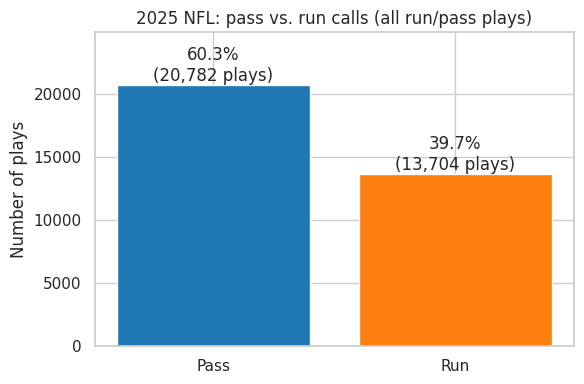

In [20]:
# Count and share of each call
counts = pbp_2025["pass_play"].map({1: "Pass", 0: "Run"}).value_counts()
shares = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=[PASS_COLOR, RUN_COLOR])
for i, (n, s) in enumerate(zip(counts.values, shares.values)):
    ax.text(i, n + 300, f"{s:.1f}%\n({n:,} plays)", ha="center")   # label each bar with % and count
ax.set_ylim(0, counts.max() * 1.2)
ax.set_ylabel("Number of plays")
ax.set_title("2025 NFL: pass vs. run calls (all run/pass plays)")
plt.tight_layout(); plt.show()

### 7b. Situation: down, distance, score, and clock
Four views of the situational factors. The top row covers down and distance, and the bottom row covers score and clock. The dashed line is the league pass rate.

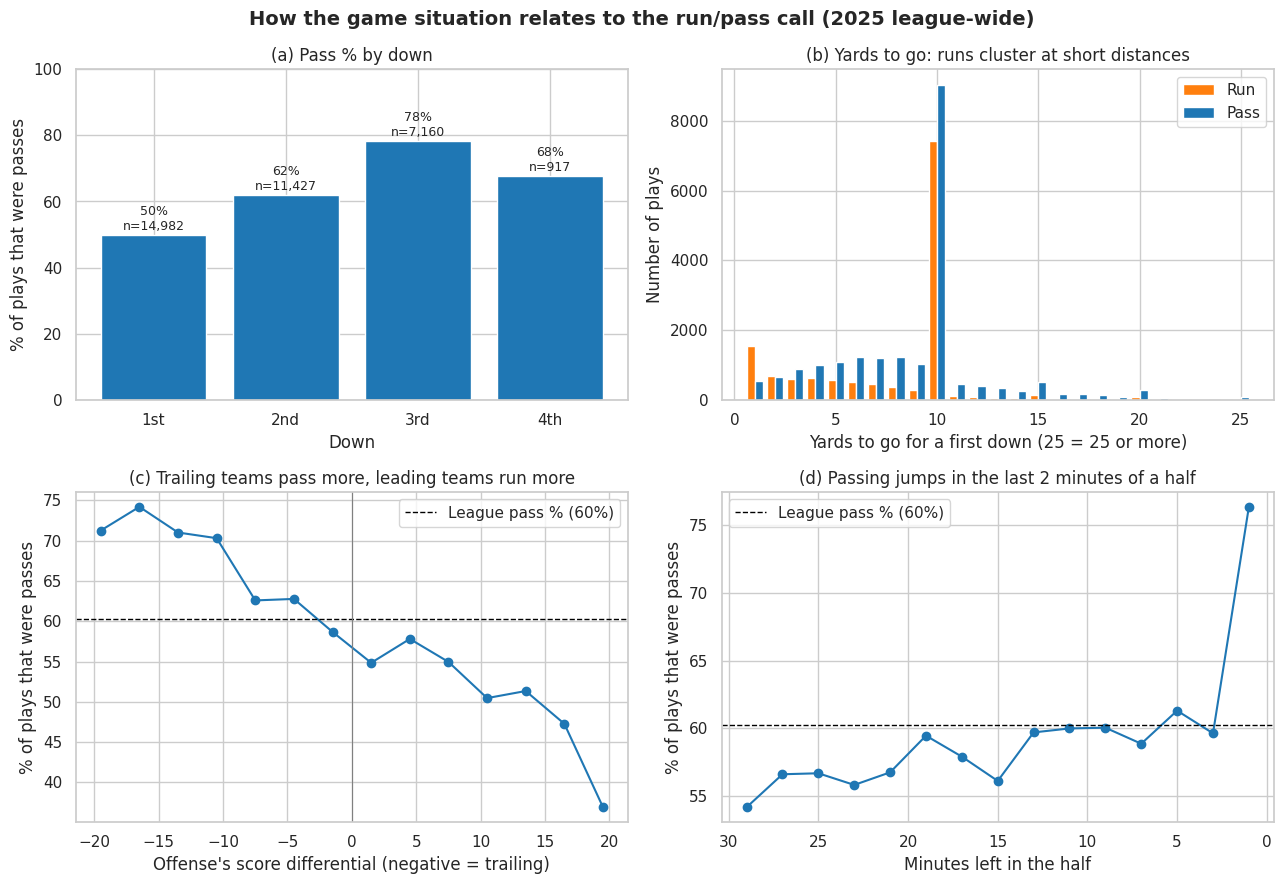

In [21]:
league_pass = pbp_2025["pass_play"].mean() * 100   # reference line for every panel
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) Pass % by down: categorical, so a bar chart with play counts
by_down = pbp_2025.groupby("down")["pass_play"].agg(["mean", "count"])
ax = axes[0, 0]
ax.bar([f"{d}{s}" for d, s in zip(by_down.index, ["st", "nd", "rd", "th"])], by_down["mean"] * 100, color=PASS_COLOR)
for i, (m, n) in enumerate(zip(by_down["mean"], by_down["count"])):
    ax.text(i, m * 100 + 1.5, f"{m*100:.0f}%\nn={n:,}", ha="center", fontsize=9)
ax.set_ylim(0, 100); ax.set_xlabel("Down"); ax.set_ylabel("% of plays that were passes")
ax.set_title("(a) Pass % by down")

# (b) Yards to go: continuous, so overlapping histograms (capped at 25 so the long tail fits)
ax = axes[0, 1]
bins = np.arange(0.5, 26.5, 1)   # one bar per yard
# Passing two lists draws run and pass bars side by side (no confusing overlap colors)
ax.hist([pbp_2025.loc[pbp_2025["pass_play"] == 0, "ydstogo"].clip(upper=25),
         pbp_2025.loc[pbp_2025["pass_play"] == 1, "ydstogo"].clip(upper=25)],
        bins=bins, color=[RUN_COLOR, PASS_COLOR], label=["Run", "Pass"])
ax.set_xlabel("Yards to go for a first down (25 = 25 or more)"); ax.set_ylabel("Number of plays")
ax.set_title("(b) Yards to go: runs cluster at short distances"); ax.legend()

# (c) Score differential: continuous, so bin it and draw a line (clip at +/- 21 to drop rare blowouts)
ax = axes[1, 0]
score_bins = pd.cut(pbp_2025["score_differential"].clip(-21, 21), bins=np.arange(-21, 24, 3), include_lowest=True)
by_score = pbp_2025.groupby(score_bins, observed=True)["pass_play"].mean() * 100
ax.plot([b.mid for b in by_score.index], by_score.values, marker="o", color=PASS_COLOR)
ax.axhline(league_pass, color="black", linestyle="--", linewidth=1, label=f"League pass % ({league_pass:.0f}%)")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Offense's score differential (negative = trailing)"); ax.set_ylabel("% of plays that were passes")
ax.set_title("(c) Trailing teams pass more, leading teams run more"); ax.legend()

# (d) Clock: minutes left in the half, in 2-minute bins (shows the 2-minute drill)
ax = axes[1, 1]
min_left = (pbp_2025["half_seconds_remaining"] / 60)
time_bins = pd.cut(min_left, bins=np.arange(0, 32, 2), include_lowest=True)
by_time = pbp_2025.groupby(time_bins, observed=True)["pass_play"].mean() * 100
ax.plot([b.mid for b in by_time.index], by_time.values, marker="o", color=PASS_COLOR)
ax.axhline(league_pass, color="black", linestyle="--", linewidth=1, label=f"League pass % ({league_pass:.0f}%)")
ax.invert_xaxis()   # read left to right as the clock runs down
ax.set_xlabel("Minutes left in the half"); ax.set_ylabel("% of plays that were passes")
ax.set_title("(d) Passing jumps in the last 2 minutes of a half"); ax.legend()

fig.suptitle("How the game situation relates to the run/pass call (2025 league-wide)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### 7c. Down & distance together
Down and distance interact: 3rd & 1-3 is a very different call from 3rd & 10+. This chart uses the same buckets as the scouting tool in Notebook 3.

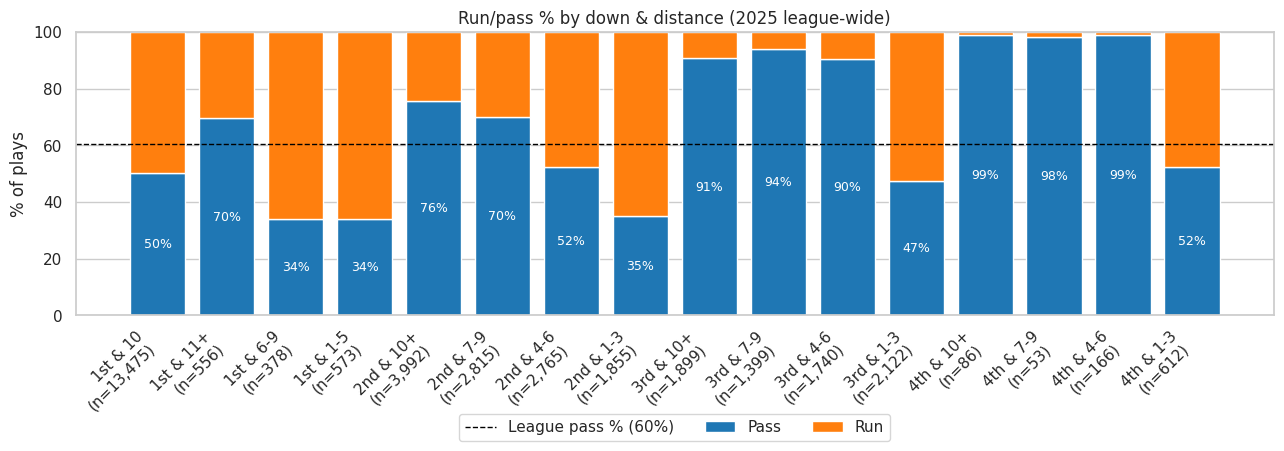

In [22]:
# Pass % and play count for each down & distance bucket, in football order
dd = pbp_2025.groupby("dd_bucket")["pass_play"].agg(["mean", "count"]).reindex(DD_ORDER).dropna()

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(dd))
ax.bar(x, dd["mean"] * 100, color=PASS_COLOR, label="Pass")
ax.bar(x, 100 - dd["mean"] * 100, bottom=dd["mean"] * 100, color=RUN_COLOR, label="Run")
for i, p in enumerate(dd["mean"] * 100):
    ax.text(i, p / 2, f"{p:.0f}%", ha="center", va="center", color="white", fontsize=9)   # pass % inside bar
ax.axhline(league_pass, color="black", linestyle="--", linewidth=1, label=f"League pass % ({league_pass:.0f}%)")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n={int(n):,})" for b, n in zip(dd.index, dd["count"])], rotation=45, ha="right")
ax.set_ylim(0, 100); ax.set_ylabel("% of plays")
ax.set_title("Run/pass % by down & distance (2025 league-wide)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3)
plt.tight_layout(); plt.show()

### 7d. Personnel: who is on the field?
Left: how often each personnel group is used. Right: how often each group passes. Only the 8 most common groups are shown; together they cover almost every play.

Top 8 groups cover 96.4% of plays


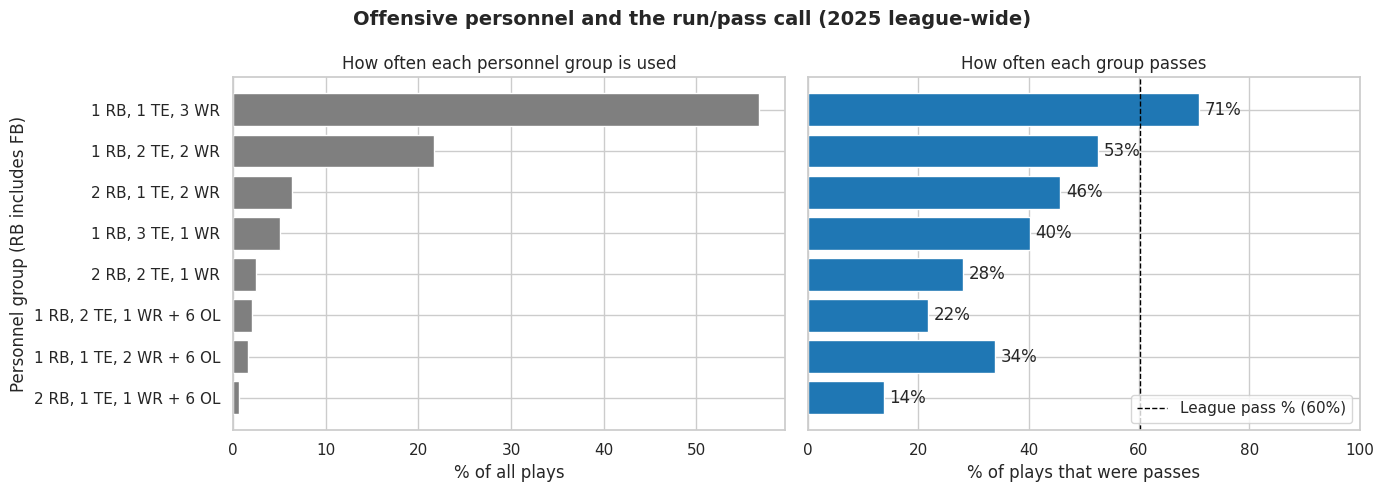

In [23]:
# Top 8 personnel groups by number of plays
top_pers = pbp_2025["personnel"].value_counts().head(8).index
pers = pbp_2025[pbp_2025["personnel"].isin(top_pers)].groupby("personnel")["pass_play"].agg(["mean", "count"])
pers = pers.reindex(top_pers)[::-1]   # most common at the top of a horizontal bar chart
print(f"Top 8 groups cover {pers['count'].sum() / len(pbp_2025):.1%} of plays")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].barh(pers.index, pers["count"] / len(pbp_2025) * 100, color="#7f7f7f")
axes[0].set_xlabel("% of all plays"); axes[0].set_title("How often each personnel group is used")
axes[1].barh(pers.index, pers["mean"] * 100, color=PASS_COLOR)
axes[1].axvline(league_pass, color="black", linestyle="--", linewidth=1, label=f"League pass % ({league_pass:.0f}%)")
for i, m in enumerate(pers["mean"] * 100):
    axes[1].text(m + 1, i, f"{m:.0f}%", va="center")   # pass % at the end of each bar
axes[1].set_xlim(0, 100); axes[1].set_xlabel("% of plays that were passes")
axes[1].set_title("How often each group passes"); axes[1].legend(loc="lower right")
axes[0].set_ylabel("Personnel group (RB includes FB)")
fig.suptitle("Offensive personnel and the run/pass call (2025 league-wide)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### 7e. Down & distance + personnel combined
The same personnel group can be a run look on 1st & 10 and a pass look on 3rd & 7-9. The heatmap shows pass % for each combination (cell text = pass %, play count). Only the 6 most common groups are shown, and gray cells have fewer than 20 plays.

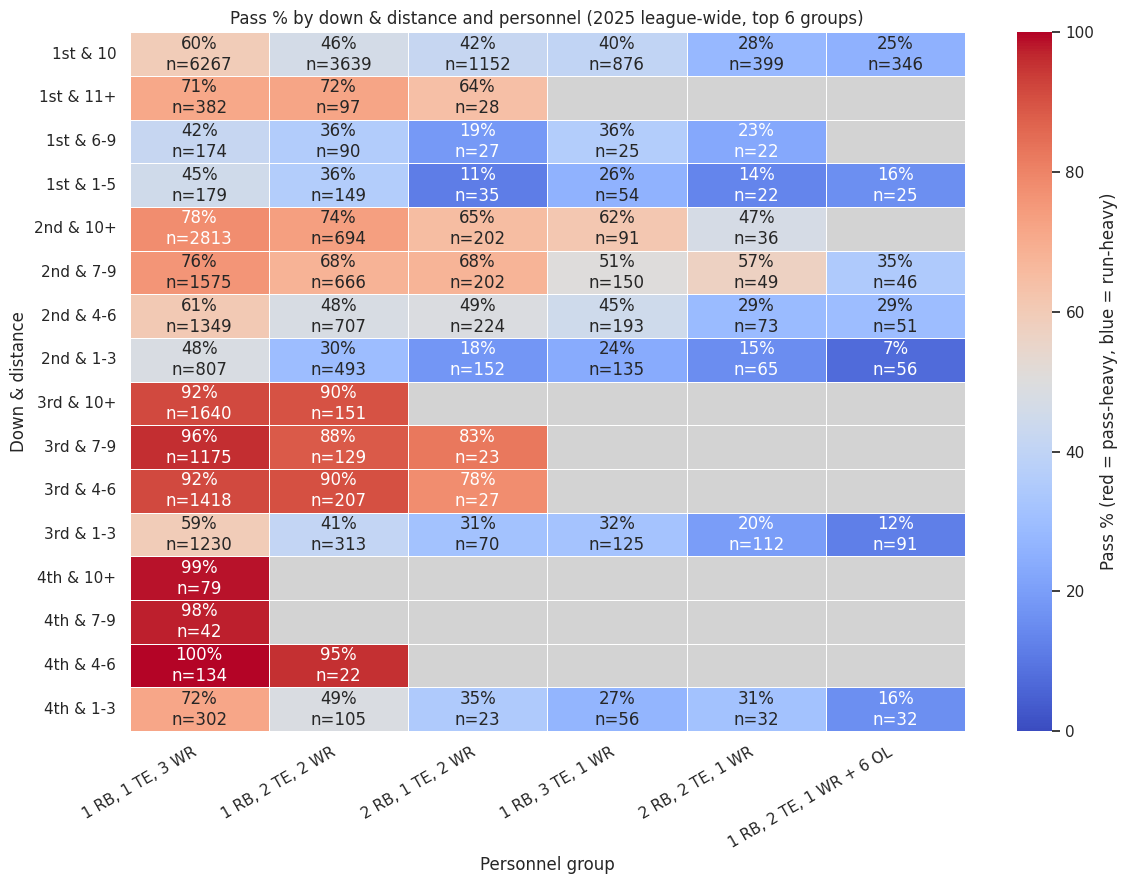

In [24]:
# Pass % and play count for each down & distance x personnel combination
top6 = pbp_2025["personnel"].value_counts().head(6).index
sub = pbp_2025[pbp_2025["personnel"].isin(top6)]
pct = sub.pivot_table(index="dd_bucket", columns="personnel", values="pass_play", aggfunc="mean") * 100
cnt = sub.pivot_table(index="dd_bucket", columns="personnel", values="pass_play", aggfunc="count")
rows = [r for r in DD_ORDER if r in pct.index]
pct, cnt = pct.reindex(index=rows, columns=top6), cnt.reindex(index=rows, columns=top6)
pct = pct.where(cnt >= 20)   # hide tiny samples so they don't look like real tendencies

# Cell text: "73%\nn=410", blank when hidden
annot = pct.copy().astype(object)
for r in pct.index:
    for c in pct.columns:
        annot.loc[r, c] = "" if np.isnan(pct.loc[r, c]) else f"{pct.loc[r, c]:.0f}%\nn={int(cnt.loc[r, c])}"

fig, ax = plt.subplots(figsize=(12, 9))
ax.set_facecolor("lightgray")   # hidden (small-sample) cells show as gray
sns.heatmap(pct, annot=annot, fmt="", cmap="coolwarm", center=50, vmin=0, vmax=100,
            cbar_kws={"label": "Pass % (red = pass-heavy, blue = run-heavy)"}, linewidths=0.5, ax=ax)
ax.set_xlabel("Personnel group"); ax.set_ylabel("Down & distance")
ax.set_title("Pass % by down & distance and personnel (2025 league-wide, top 6 groups)")
ax.grid(False)   # turn off the background grid so it doesn't cut through the cells
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

### 7f. Feature correlations
This chart checks two things: which features move with the target, and which features overlap with each other. Overlapping features (for example, `qtr` and `game_seconds_remaining`) carry the same information, which matters when reading logistic regression coefficients in Notebook 2.

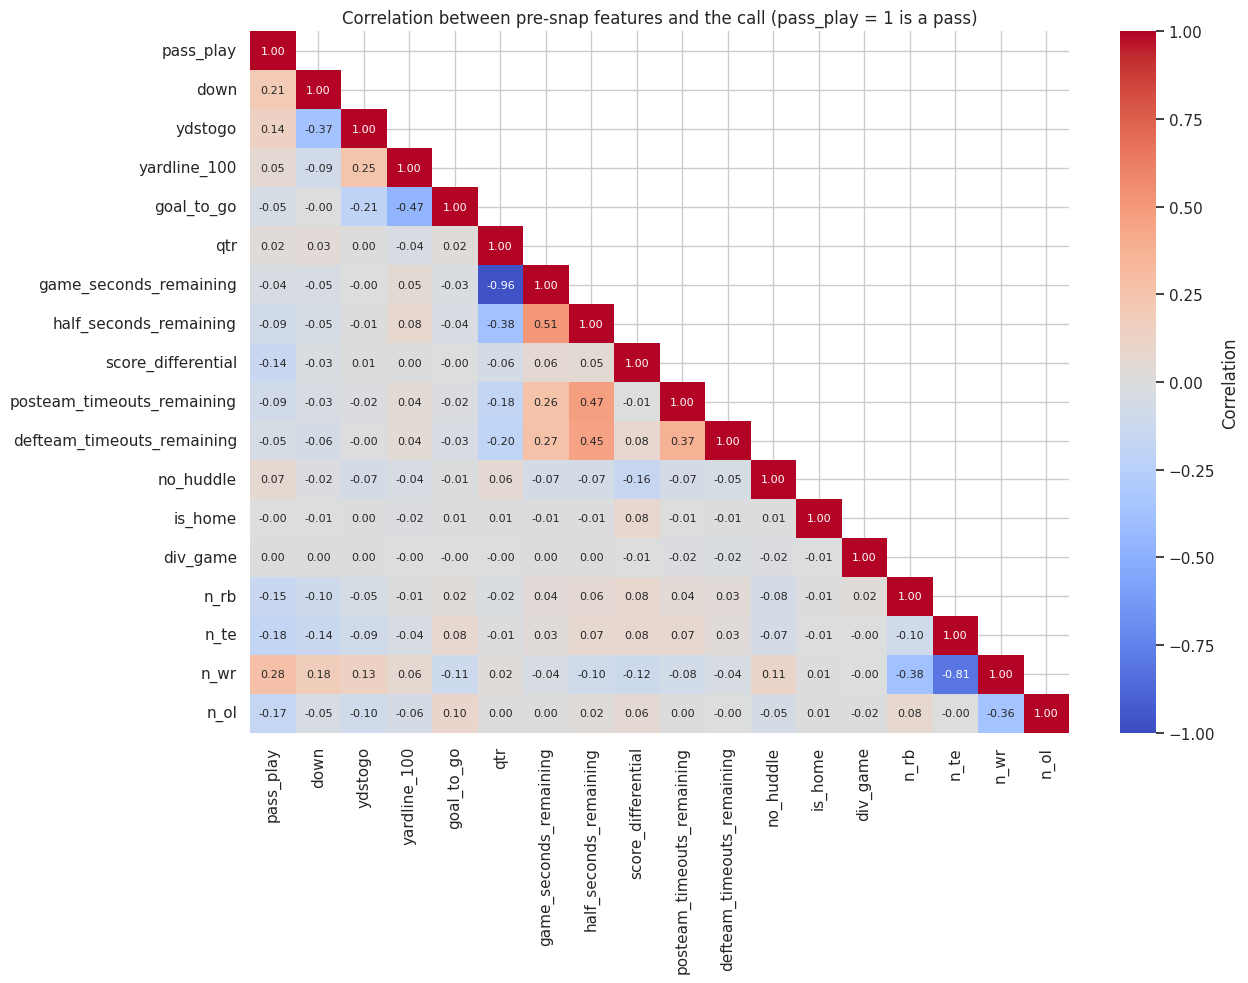

In [25]:
# Every numeric feature the models will use, plus the target
model_cols = ["pass_play", "down", "ydstogo", "yardline_100", "goal_to_go", "qtr",
              "game_seconds_remaining", "half_seconds_remaining", "score_differential",
              "posteam_timeouts_remaining", "defteam_timeouts_remaining", "no_huddle",
              "is_home", "div_game", "n_rb", "n_te", "n_wr", "n_ol"]
corr = pbp_2025[model_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # hide the upper triangle (it's a mirror image)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 8}, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlation between pre-snap features and the call (pass_play = 1 is a pass)")
plt.tight_layout(); plt.show()

In [26]:
# Correlation of each feature with the target alone, strongest first
print(corr["pass_play"].drop("pass_play").sort_values(key=abs, ascending=False).round(3).to_string())

n_wr                          0.281
down                          0.210
n_te                         -0.183
n_ol                         -0.168
n_rb                         -0.148
score_differential           -0.144
ydstogo                       0.136
posteam_timeouts_remaining   -0.093
half_seconds_remaining       -0.092
no_huddle                     0.066
yardline_100                  0.055
defteam_timeouts_remaining   -0.054
goal_to_go                   -0.050
game_seconds_remaining       -0.043
qtr                           0.025
is_home                      -0.005
div_game                      0.001


### 7g. The benchmark: how well does `xpass` separate runs from passes?
`xpass` is nflfastR's probability that a play is a dropback. If its histograms for runs and passes barely overlapped, a pre-snap model could be nearly perfect. The large overlap shows how hard this problem is, even for a professional model.

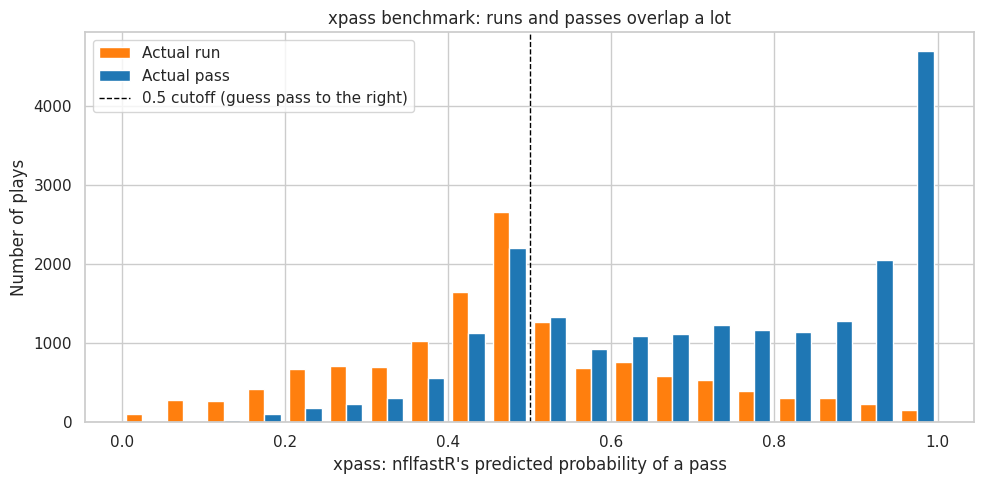

xpass accuracy on all 2025 plays: 0.710  (always-pass baseline: 0.603)


In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, 1, 21)   # 20 bins, 5 percentage points each
# Side-by-side bars: orange = plays that were actually runs, blue = actually passes
ax.hist([pbp_2025.loc[pbp_2025["pass_play"] == 0, "xpass"].dropna(),
         pbp_2025.loc[pbp_2025["pass_play"] == 1, "xpass"].dropna()],
        bins=bins, color=[RUN_COLOR, PASS_COLOR], label=["Actual run", "Actual pass"])
ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="0.5 cutoff (guess pass to the right)")
ax.set_xlabel("xpass: nflfastR's predicted probability of a pass"); ax.set_ylabel("Number of plays")
ax.set_title("xpass benchmark: runs and passes overlap a lot")
ax.legend(); plt.tight_layout(); plt.show()

# Accuracy of the benchmark on the full season (plays with xpass only)
has_xp = pbp_2025["xpass"].notna()
xp_acc = ((pbp_2025.loc[has_xp, "xpass"] >= 0.5).astype(int) == pbp_2025.loc[has_xp, "pass_play"]).mean()
print(f"xpass accuracy on all 2025 plays: {xp_acc:.3f}  (always-pass baseline: {pbp_2025['pass_play'].mean():.3f})")

## Key Findings from the Data (plain language)

**1. The bar to beat is 60%.** Teams called a pass on 60.3% of plays. A "model" that always guesses pass is right 60% of the time.

**2. Down & distance is the strongest situational signal**
- 1st down is a coin flip (50% pass). 3rd down is 78% pass.
- 3rd & 4+ yards is 90–94% pass, and 4th & 4+ is 98–99% pass.
- Short yardage (1–3 yards to go) leans run on every down except 3rd (47% pass).

**3. Personnel is almost as strong**
- 1 RB, 1 TE, 3 WR is on the field for 56% of plays and passes 71% of the time.
- Every other common group passes *less* than the league average.
- Packages with a 6th offensive lineman run the ball 66–86% of the time.

**4. Down & distance and personnel work best together.** The same group can mean opposite things. For example, 1 RB, 2 TE, 2 WR passes 46% of the time on 1st & 10 but 90% on 3rd & 4-6. This is why the scouting tool in Notebook 3 looks at the two together.

**5. Score and clock matter.**
- Teams trailing by 9 or more pass 70–74% of the time.
- Teams leading by more than 15 pass less than half the time.
- In the last 2 minutes of a half, passing jumps to 76%.

**6. Some factors barely matter.** No-huddle has only a small effect (r = 0.07), and home/away and division games show almost no relationship with the call (r ≈ 0.00). Don't expect them to help the models much.

**7. Some features overlap, which matters for Notebook 2.**
- `qtr` and `game_seconds_remaining` are almost the same information.
- `n_te` and `n_wr` trade off directly (r = -0.81). With 11 players on the field, adding a TE usually means removing a WR.
- That's why `n_rb` is left out of the models as the reference position, and why personnel effects are read as *swaps*.

**8. Where predictions will be hardest:** 1st & 10 makes up 39% of all plays and is a 50/50 call. Even nflfastR's professional `xpass` model is right only 71.0% of the time over the full season, so a realistic target is roughly 65–71% accuracy, not 90%.

**9. Note for the train/test split:** 1,688 plays (about 5%) are playoff games (weeks 19–22). A test set made of late-season weeks will include playoff play-calling.

## 9. Save the clean data for Notebooks 2 and 3
Saving once means the next two notebooks load the same cleaned plays without re-downloading or re-cleaning.

In [29]:
from google.colab import drive
from pathlib import Path

# Connect Colab to your Google Drive
drive.mount('/content/drive')

# Save inside a folder in YOUR Drive -- permanent, and visible to every notebook
DATA_DIR = Path("/content/drive/MyDrive/capstone/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Save as CSV -- opens in Excel/Sheets; index=False skips the extra row-number column
pbp_2025.to_csv(DATA_DIR / "pbp_2025_clean.csv", index=False)
print(f"Saved {len(pbp_2025):,} plays x {pbp_2025.shape[1]} columns to {DATA_DIR / 'pbp_2025_clean.csv'}")

Mounted at /content/drive
Saved 34,486 plays x 32 columns to /content/drive/MyDrive/capstone/data/pbp_2025_clean.csv
